In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
#step 2 - Implement the 6 activation functions
# 1. Sigmoid
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


# 2. Tanh
def tanh(x):
    return np.tanh(x)


# 3. ReLU
def relu(x):
    return np.maximum(0, x)


# 4. Leaky ReLU
def leaky_relu(x, alpha=0.01):
    return np.where(x > 0, x, alpha * x)


# 5. GELU (exact version)
def gelu(x):
    return 0.5 * x * (1 + np.vectorize(__import__('math').erf)(x / np.sqrt(2)))


# 6. SiLU (also called Swish)
def silu(x):
    return x * sigmoid(x)


print("All six activation functions implemented!")

All six activation functions implemented!


In [7]:
#step 3 - Implement Derivatives
# 1. Sigmoid derivative
def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)


# 2. Tanh derivative
def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2


# 3. ReLU derivative
def relu_derivative(x):
    return np.where(x > 0, 1.0, 0.0)


# 4. Leaky ReLU derivative
def leaky_relu_derivative(x, alpha=0.01):
    return np.where(x > 0, 1.0, alpha)


# 5. GELU derivative (exact)
def gelu_derivative(x):
    pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
    cdf = 0.5 * (1 + np.vectorize(__import__('math').erf)(x / np.sqrt(2)))
    return cdf + x * pdf


# 6. SiLU derivative
def silu_derivative(x):
    s = sigmoid(x)
    return s + x * s * (1 - s)


print("All six derivatives implemented!")

All six derivatives implemented!


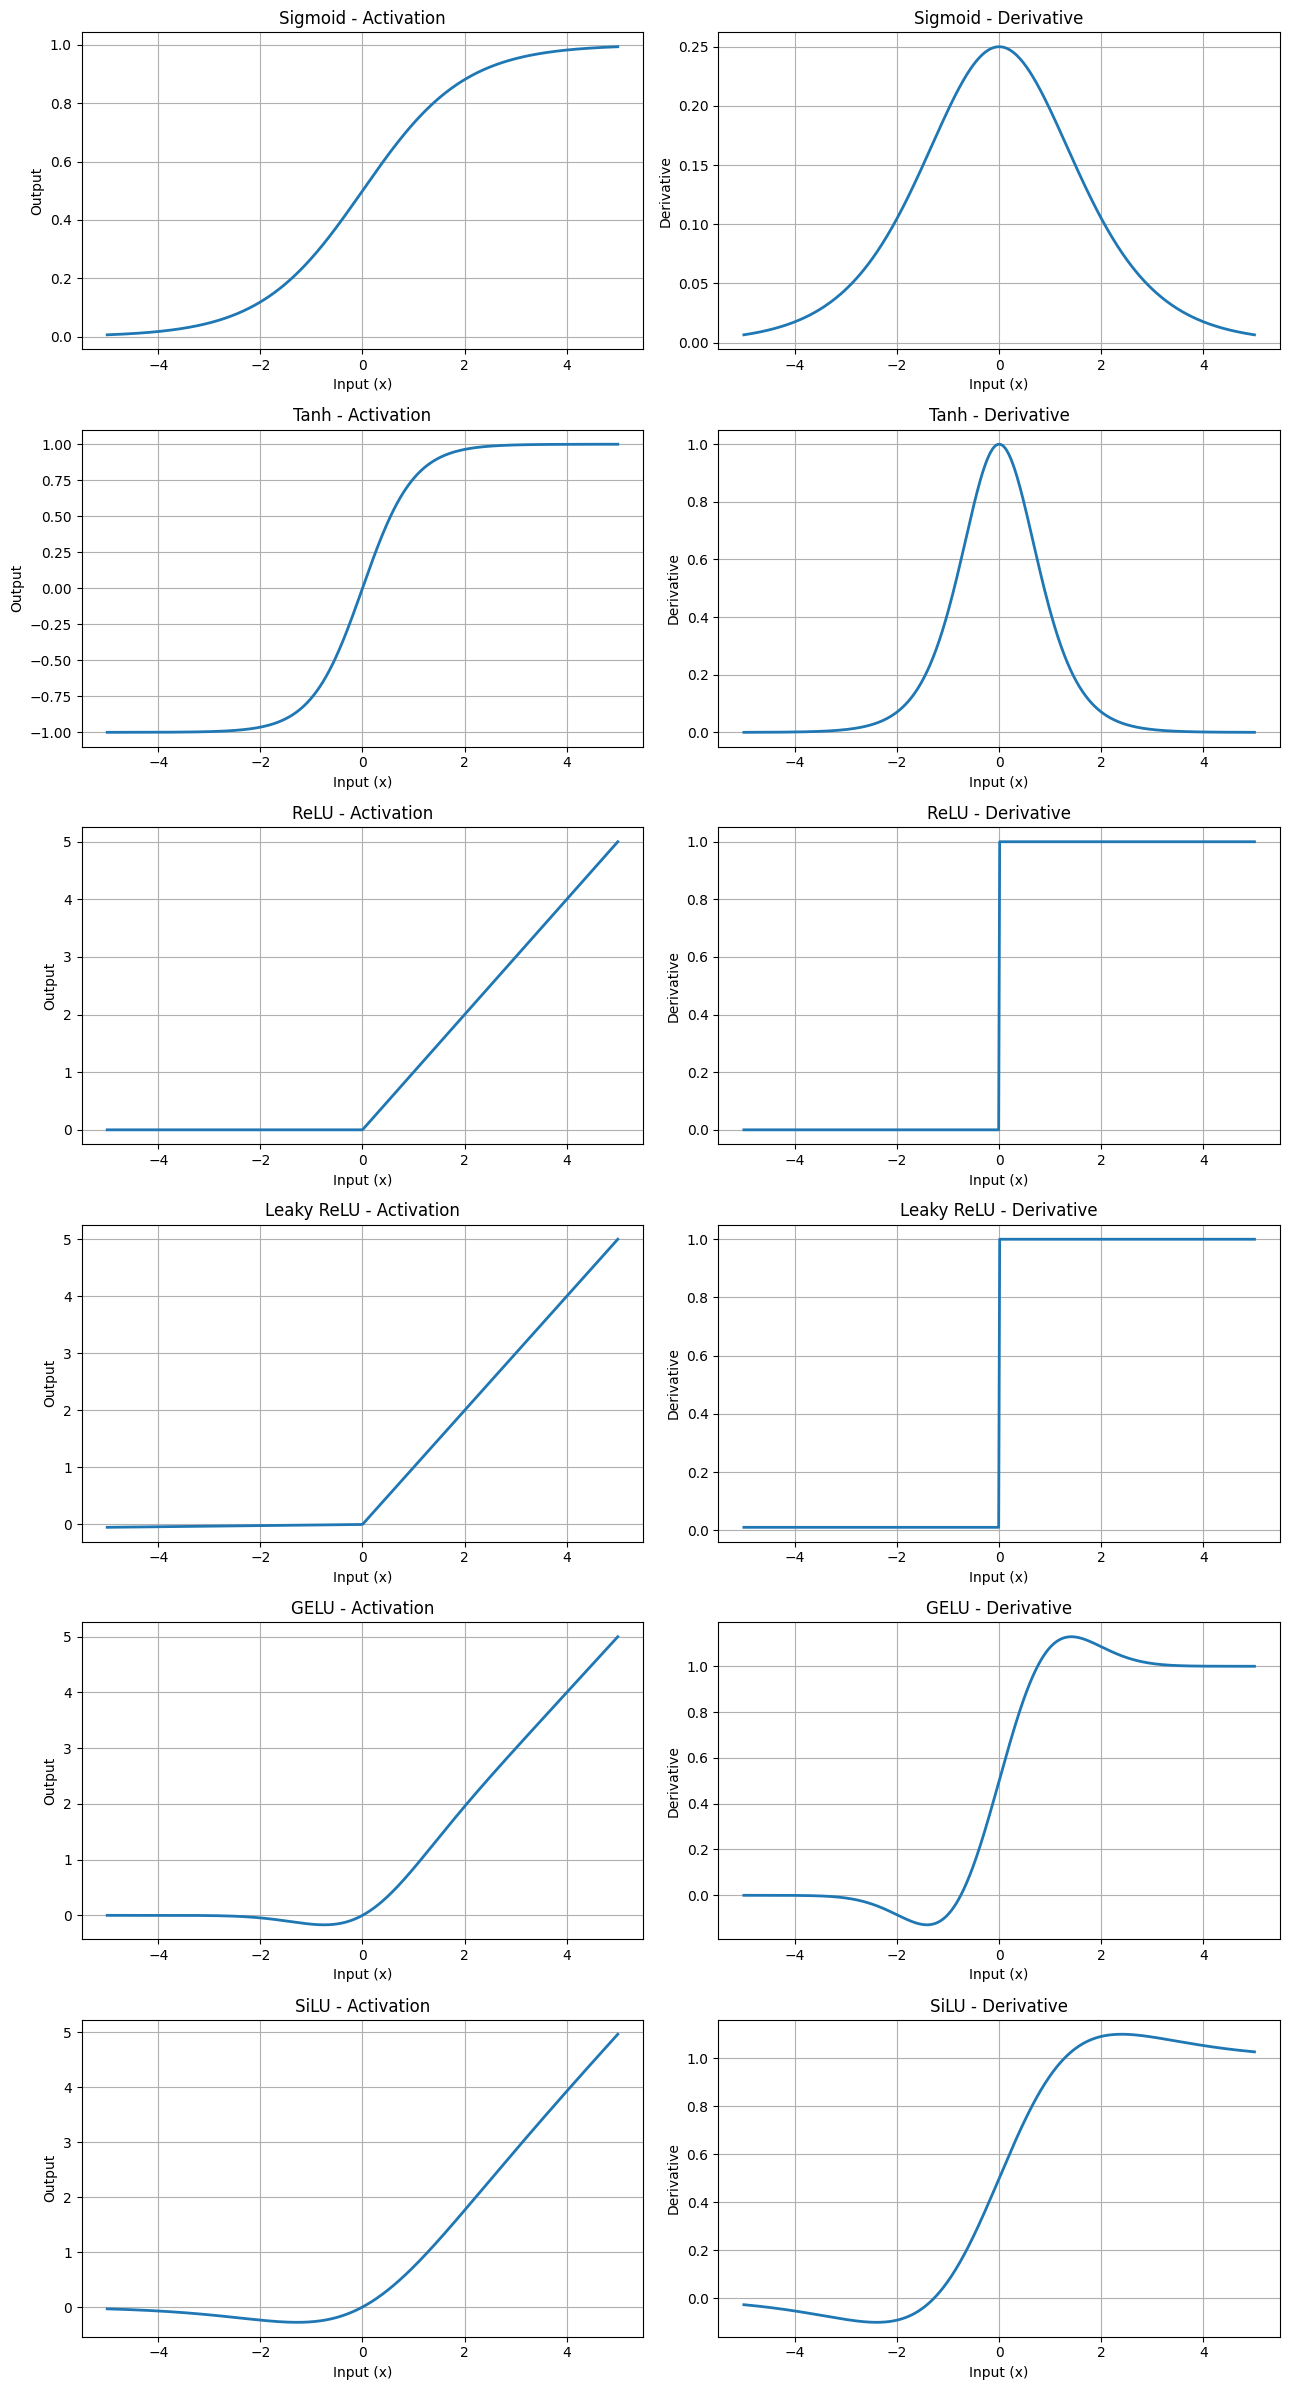

In [9]:
#step 4 - Visualize activation functions and derivatives
x = np.linspace(-5, 5, 500)

activations = {
    "Sigmoid": (sigmoid, sigmoid_derivative),
    "Tanh": (tanh, tanh_derivative),
    "ReLU": (relu, relu_derivative),
    "Leaky ReLU": (leaky_relu, leaky_relu_derivative),
    "GELU": (gelu, gelu_derivative),
    "SiLU": (silu, silu_derivative)
}

fig, axes = plt.subplots(6, 2, figsize=(13, 24))

for i, (name, (func, derivative)) in enumerate(activations.items()):

    # Activation function
    axes[i, 0].plot(x, func(x), linewidth=2)
    axes[i, 0].set_title(name + " - Activation")
    axes[i, 0].set_xlabel("Input (x)")
    axes[i, 0].set_ylabel("Output")
    axes[i, 0].grid(True)

    # Derivative
    axes[i, 1].plot(x, derivative(x), linewidth=2)
    axes[i, 1].set_title(name + " - Derivative")
    axes[i, 1].set_xlabel("Input (x)")
    axes[i, 1].set_ylabel("Derivative")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

In [11]:
activations = {
    "sigmoid": (sigmoid, sigmoid_derivative),
    "tanh": (tanh, tanh_derivative),
    "relu": (relu, relu_derivative),
    "leaky_relu": (leaky_relu, leaky_relu_derivative),
    "gelu": (gelu, gelu_derivative),
    "silu": (silu, silu_derivative)
}

print(activations.keys())

dict_keys(['sigmoid', 'tanh', 'relu', 'leaky_relu', 'gelu', 'silu'])


In [12]:
#step 5 - Implement artificial neuron 

class ArtificialNeuron:

    def __init__(self, weights, bias, activation="sigmoid"):

        self.weights = np.array(weights, dtype=float)
        self.bias = bias

        if activation not in activations:
            raise ValueError(
                f"Unknown activation: {activation}. "
                f"Available: {list(activations.keys())}"
            )

        self.activation_name = activation
        self.activation_function = activations[activation][0]

    def forward(self, inputs):

        inputs = np.array(inputs, dtype=float)

        if len(inputs) != len(self.weights):
            raise ValueError("Inputs and weights must have equal lengths")

        z = np.dot(inputs, self.weights) + self.bias

        output = self.activation_function(z)

        return z, output


inputs = [0.5, 0.8, 0.2]
weights = [0.4, 0.6, 0.3]
bias = 0.2

neuron = ArtificialNeuron(weights, bias, activation="sigmoid")

z, output = neuron.forward(inputs)

print("Weighted sum:", z)
print("Neuron output:", output)

Weighted sum: 0.94
Neuron output: 0.7190996574163839


In [14]:
# step 6 - Investigate gradient flow
gradient_results = []

for name, (func, derivative) in activations.items():

    gradients = derivative(x)

    gradient_results.append({
        "Activation": name,
        "Mean Absolute Derivative": np.mean(np.abs(gradients)),
        "Maximum Derivative": np.max(np.abs(gradients)),
        "Near-Zero Gradient (%)": np.mean(
            np.abs(gradients) < 0.001
        ) * 100
    })

gradient_df = pd.DataFrame(gradient_results)

print(gradient_df.round(4).to_string(index=False))

Activation  Mean Absolute Derivative  Maximum Derivative  Near-Zero Gradient (%)
   sigmoid                    0.0985              0.2500                     0.0
      tanh                    0.1996              0.9999                    17.2
      relu                    0.5000              1.0000                    50.0
leaky_relu                    0.5050              1.0000                     0.0
      gelu                    0.5339              1.1289                    12.2
      silu                    0.5490              1.0998                     0.0


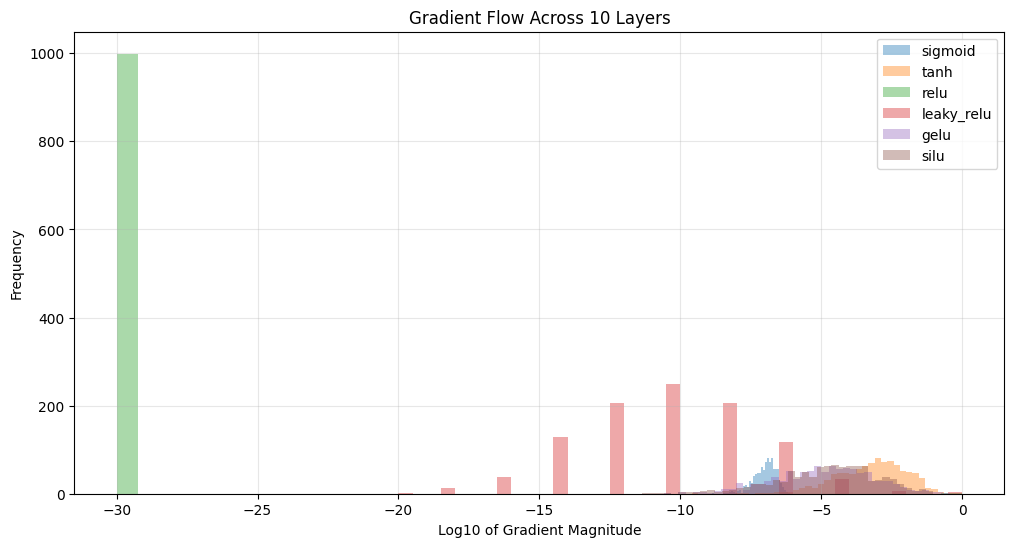

In [16]:
# step 7 - Visualize gradient flow with multiple layers
np.random.seed(42)

num_layers = 10
num_trials = 1000

gradient_flow = {}

for name, (func, derivative) in activations.items():

    gradients = np.ones(num_trials)

    for layer in range(num_layers):

        z = np.random.randn(num_trials)

        local_gradient = derivative(z)

        gradients *= local_gradient

    gradient_flow[name] = np.abs(gradients)


plt.figure(figsize=(12, 6))

for name, values in gradient_flow.items():

    plt.hist(
        np.log10(values + 1e-30),
        bins=40,
        alpha=0.4,
        label=name
    )

plt.xlabel("Log10 of Gradient Magnitude")
plt.ylabel("Frequency")
plt.title("Gradient Flow Across 10 Layers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Note: Zero gradients are represented at approximately -30 on the logarithmic scale because a small epsilon was added before taking the logarithm

# step 8 - Compare and Interpret results
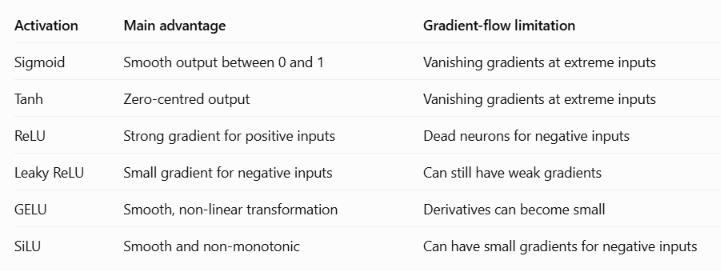

# step 9 - Final conclusion 

1. An artificial neuron calculates the weighted sum of inputs, adds a bias, and applies an activation function to produce its output.

2. Different activation functions produce different outputs for the same inputs, weights, and bias.

3. **Sigmoid** produces outputs between 0 and 1. Its derivatives become very small for large positive and negative inputs, which can lead to the vanishing gradient problem.

4. **Tanh** produces outputs between -1 and 1 and is zero-centred. However, its gradients become very small in the saturation regions.

5. **ReLU** provides a gradient of 1 for positive inputs, making it useful for training deep networks. However, its gradient becomes zero for negative inputs, which can cause dead neurons.

6. **Leaky ReLU** addresses the zero-gradient problem of ReLU by allowing a small gradient for negative inputs. However, repeated multiplication of small gradients can still lead to vanishing gradients.

7. **GELU and SiLU** provide smooth, non-linear activation behaviour. Their derivatives can sometimes exceed 1, allowing gradients to be amplified in certain regions.

8. The gradient-flow experiment demonstrates that activation derivatives influence how gradients propagate through multiple layers. ReLU can produce exactly zero gradients, while Sigmoid and Tanh can produce very small gradients. Leaky ReLU reduces the zero-gradient problem, but does not completely eliminate vanishing gradients.

9. Therefore, choosing an appropriate activation function is important for maintaining effective gradient propagation and improving neural network training.